# Turtle Breakout 09 — risk per trade 1%–100% on BTC: long only vs long + stop-and-reverse

Note: `discussions/Turtle_Breakout/011_claude_tb09_note.md`. Code: `src/data_engineering/modeling/turtle_sizing.py` (`trade_list`, `equity_from_trades`, `sweep_trades`).

**Descriptive only — no decision gate, not for implementation** (choosing $f$ in-sample on a variant that itself failed G1 is double overfitting).
Same BTC window and sizing as TB 08: $u = f\cdot \mathrm{HWM}/(2\,\mathrm{ATR})$ for every trade. The reverse short (TB 07 rules) is sized the same way with the ATR of its own day.
Sweeps P (125× cap, HWM), C3 (3× cap), EQ (current-equity sizing), each for both trade lists: 600 backtests.

Environment: `TB01_DATA_DIR` (default `BINANCE_UM_DIR\long`), `TB09_SYNTHETIC=1`.

In [1]:
import os, sys, json, subprocess, tempfile, warnings, platform, math
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from dotenv import load_dotenv
warnings.filterwarnings('ignore', category=RuntimeWarning)
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 40); pd.set_option('display.max_rows', 150)
ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / 'src' / 'data_engineering').is_dir(): ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src')); load_dotenv(ROOT / '.env')
from data_engineering.modeling import turtle_breakout as tb, turtle_trade_features as tf, turtle_sizing as ts, turtle_reverse as tr

SYNTHETIC = os.getenv('TB09_SYNTHETIC', '0') == '1'
P = tb.Params(); SP = ts.SParams(); RP = tr.RParams()
if SYNTHETIC:
    OUT = Path(tempfile.mkdtemp(prefix='tb09-')) / '09'; SP = ts.SParams(n_boot=500)
    b = tb.synthetic_5m(2400, seed=11, trend=0.01, start='2020-01-01'); f = tb.synthetic_funding(b, 0.0001)
else:
    OUT = ROOT / 'notebooks' / 'Turtle_Breakout' / '09'
    base = Path(os.environ['BINANCE_UM_DIR']) if os.environ.get('BINANCE_UM_DIR') else Path(os.environ['DERIBIT_DATA_ROOT']).parent / 'Binance'
    DATA = Path(os.environ.get('TB01_DATA_DIR', str(base / 'long')))
    b, _ = tf.load_um(DATA / 'BTCUSDT_um_1m.parquet')
    f = tb.funding_events(pd.read_parquet(DATA / 'basis' / 'funding' / 'BTCUSDT_funding.parquet'))
OUT.mkdir(parents=True, exist_ok=True)
env = os.environ.copy(); env['PYTHONPATH'] = str(ROOT / 'src') + os.pathsep + env.get('PYTHONPATH', '')
chk = subprocess.run([sys.executable, '-m', 'unittest', 'discover', '-s', 'tests', '-p', 'test_turtle_sizing.py'], cwd=str(ROOT), env=env, capture_output=True, text=True)
print(chk.stderr.strip().splitlines()[-1]); assert chk.returncode == 0
D = tb.prepare_asset('BTC', b, f, P)
START = b.index[0] + pd.Timedelta(days=30)
L0 = ts.trade_list(D, P, START, RP, with_reverse=False)
L1 = ts.trade_list(D, P, START, RP, with_reverse=True)
print('BTC', START, '->', b.index[-1], '| longs', len(L0), '| reverse shorts', int((L1.kind == 'reverse').sum()))
print('days in a position: long only', round(float(((L0.jx - L0.je) / 288).sum()), 1), '| long + reverse', round(float(((L1.jx - L1.je) / 288).sum()), 1),
      '| of', round((b.index[-1] - START).days, 1))

OK
BTC 2020-01-31 00:05:00+00:00 -> 2026-10-24 00:00:00+00:00 | longs 54 | reverse shorts 33
days in a position: long only 985.8 | long + reverse 1590.8 | of 2457


## 1. Sweeps (600 backtests) and check against TB 08

In [2]:
TAB, CUR = {}, {}
for name, cap, sb in (('P', SP.max_lev_primary, 'hwm'), ('C3', SP.max_lev_c3, 'hwm'), ('EQ', SP.max_lev_primary, 'equity')):
    for v, L in (('long', L0), ('long_rev', L1)):
        TAB[(name, v)], CUR[(name, v)] = ts.sweep_trades(D, L, P, START, cap, sb)
    print(name, 'done')
if not SYNTHETIC:
    for name in ('P', 'C3', 'EQ'):
        ref = pd.read_csv(ROOT / 'notebooks' / 'Turtle_Breakout' / '08' / f'08_sweep_{name}.csv')
        dif = np.nanmax(np.abs(ref.final_equity.to_numpy() - TAB[(name, 'long')].final_equity.to_numpy()) / ref.final_equity.abs().clip(lower=1).to_numpy())
        print(f'{name}: long-only sweep vs TB 08, max relative difference in final equity = {dif:.2e}')

P done
C3 done
EQ done
P: long-only sweep vs TB 08, max relative difference in final equity = 9.71e-17
C3: long-only sweep vs TB 08, max relative difference in final equity = 1.57e-16
EQ: long-only sweep vs TB 08, max relative difference in final equity = 2.48e-16


## 2. Side by side at selected risk levels

In [3]:
sel = [0.01, 0.02, 0.03, 0.05, 0.07, 0.1, 0.12, 0.13, 0.15, 0.2, 0.25, 0.3, 0.4, 0.5, 0.75, 1.0]
cols = ['cagr', 'sharpe', 'max_dd', 'calmar', 'ruined', 'worst_trade_pct_equity', 'max_gross_lev']
SIDE = {}
for name in ('P', 'C3', 'EQ'):
    a = TAB[(name, 'long')].set_index('f')[cols]; c = TAB[(name, 'long_rev')].set_index('f')[cols + ['pnl_reverse']]
    S = pd.concat({'long': a, 'long_rev': c}, axis=1)
    S = S[S.index.round(3).isin([round(x, 3) for x in sel])]
    SIDE[name] = S; print(name); display(S.round(3))

P


long                                                                  long_rev                                                                               
       cagr sharpe max_dd calmar ruined worst_trade_pct_equity max_gross_lev     cagr sharpe max_dd calmar ruined worst_trade_pct_equity max_gross_lev   pnl_reverse
f                                                                                                                                                                   
0.01  0.060  0.970 -0.108  0.552  False                 -0.011         0.348    0.078  1.084 -0.086  0.906  False                 -0.011         0.321  1.474312e+04
0.02  0.123  0.996 -0.208  0.589  False                 -0.025         0.699    0.161  1.116 -0.164  0.985  False                 -0.024         0.597  3.812752e+04
0.03  0.188  1.017 -0.300  0.625  False                 -0.040         1.054    0.250  1.145 -0.234  1.067  False                 -0.039         0.841  7.532708e+04
0.05  0.325  1.048 -0.468  0.694  False                 -0.081         2.292    0.441  1.196 -0.357  1.235  False                 -0.075         1.365  2.286831e+05
0.07  0.472  1.068 -0.619  0.762  False                 -0.139         4.421    0.652  1.240 -0.464  1.406  False                 -0.121         2.008  6.155841e+05
0.10  0.709  1.065 -0.826  0.858  False                 -0.279        13.027    1.011  1.303 -0.604  1.673  False                 -0.216         3.417  2.523247e+06
0.12  0.878  1.018 -0.955  0.919  False                 -0.596        46.198    1.280  1.345 -0.689  1.858  False                 -0.303         4.954  6.250722e+06
0.13 -1.000  0.378 -1.000 -1.000   True                 -1.322      9389.678    1.425  1.366 -0.729  1.953  False                 -0.357         5.986  9.725940e+06
0.15 -1.000  0.429 -1.000 -1.000   True                 -1.283        37.328    1.735  1.412 -0.826  2.099  False                 -0.526         8.966  2.313630e+07
0.20 -1.000  0.031 -1.000 -1.000   True                 -2.209        77.687   -1.000  0.478 -1.000 -1.000   True                 -2.283       514.304 -7.910637e+05
0.25 -1.000  0.498 -1.000 -1.000   True                 -1.817        63.376   -1.000  0.632 -1.000 -1.000   True                 -1.266       182.541 -2.115482e+06
0.30 -1.000  0.502 -1.000 -1.000   True                -14.692        13.693   -1.000  0.661 -1.000 -1.000   True                 -3.692       105.056 -5.015923e+06
0.40 -1.000  0.783 -1.000 -1.000   True                 -2.274        71.724   -1.000  0.943 -1.000 -1.000   True                 -1.744        64.644 -7.618128e+06
0.50 -1.000  0.845 -1.000 -1.000   True                 -8.502        62.751   -1.000  0.451 -1.000 -1.000   True                 -7.732        29.609 -6.512025e+04
0.75 -1.000  0.467 -1.000 -1.000   True                 -1.446       175.027   -1.000 -0.163 -1.000 -1.000   True                 -5.335      2038.146  8.664922e+03
1.00 -1.000  0.540 -1.000 -1.000   True                 -4.285       252.820   -1.000  0.009 -1.000 -1.000   True                 -2.289       379.897 -1.491675e+05

C3


long                                                                  long_rev                                                                              
       cagr sharpe max_dd calmar ruined worst_trade_pct_equity max_gross_lev     cagr sharpe max_dd calmar ruined worst_trade_pct_equity max_gross_lev  pnl_reverse
f                                                                                                                                                                  
0.01  0.060  0.970 -0.108  0.552  False                 -0.011         0.348    0.078  1.084 -0.086  0.906  False                 -0.011         0.321    14743.120
0.02  0.123  0.996 -0.208  0.589  False                 -0.025         0.699    0.161  1.116 -0.164  0.985  False                 -0.024         0.597    38127.518
0.03  0.188  1.017 -0.300  0.625  False                 -0.040         1.054    0.250  1.145 -0.234  1.067  False                 -0.039         0.841    75327.082
0.05  0.325  1.048 -0.468  0.694  False                 -0.081         2.292    0.441  1.196 -0.357  1.235  False                 -0.075         1.365   228683.082
0.07  0.442  1.037 -0.619  0.714  False                 -0.139         2.963    0.652  1.240 -0.464  1.406  False                 -0.121         2.008   615584.115
0.10  0.517  0.962 -0.781  0.663  False                 -0.260         3.378    1.005  1.300 -0.604  1.663  False                 -0.216         3.315  2421502.710
0.12  0.468  0.882 -0.858  0.545  False                 -0.336         3.578    1.076  1.262 -0.689  1.562  False                 -0.303         3.889  2813179.821
0.13  0.354  0.776 -0.907  0.390  False                 -0.414         4.035    1.042  1.223 -0.728  1.431  False                 -0.353         4.244  2413964.261
0.15  0.230  0.666 -0.952  0.241  False                 -0.448         4.036    0.936  1.146 -0.804  1.165  False                 -0.353         4.493  1883945.401
0.20  0.217  0.665 -0.964  0.226  False                 -0.470         4.356    0.510  0.946 -0.900  0.567  False                 -0.500         6.431   682826.521
0.25  0.221  0.674 -0.970  0.228  False                 -0.470         4.356    0.477  0.933 -0.921  0.518  False                 -0.500         6.431   527496.264
0.30  0.222  0.676 -0.971  0.228  False                 -0.470         4.356    0.461  0.927 -0.923  0.499  False                 -0.500         6.431   484574.852
0.40  0.213  0.670 -0.971  0.220  False                 -0.470         4.356    0.422  0.909 -0.923  0.457  False                 -0.500         6.431   397897.957
0.50  0.213  0.669 -0.971  0.219  False                 -0.470         4.356    0.422  0.909 -0.923  0.457  False                 -0.500         6.431   397897.957
0.75  0.213  0.669 -0.971  0.219  False                 -0.470         4.356    0.422  0.909 -0.923  0.457  False                 -0.500         6.431   397897.957
1.00  0.213  0.669 -0.971  0.219  False                 -0.470         4.356    0.422  0.909 -0.923  0.457  False                 -0.500         6.431   397897.957

EQ


long                                                                  long_rev                                                                              
       cagr sharpe max_dd calmar ruined worst_trade_pct_equity max_gross_lev     cagr sharpe max_dd calmar ruined worst_trade_pct_equity max_gross_lev  pnl_reverse
f                                                                                                                                                                  
0.01  0.057  0.966 -0.104  0.550  False                 -0.011         0.313    0.075  1.077 -0.083  0.905  False                 -0.011         0.313    13974.936
0.02  0.112  0.986 -0.192  0.583  False                 -0.022         0.576    0.150  1.101 -0.153  0.978  False                 -0.022         0.576    33669.865
0.03  0.164  1.002 -0.268  0.612  False                 -0.033         0.801    0.223  1.120 -0.213  1.048  False                 -0.033         0.801    60750.036
0.05  0.261  1.024 -0.394  0.663  False                 -0.054         1.228    0.365  1.149 -0.311  1.175  False                 -0.055         1.228   144535.560
0.07  0.348  1.037 -0.495  0.704  False                 -0.076         1.714    0.500  1.169 -0.389  1.287  False                 -0.077         1.714   280290.735
0.10  0.459  1.044 -0.613  0.749  False                 -0.109         2.437    0.685  1.189 -0.482  1.421  False                 -0.115         2.499   603568.127
0.12  0.520  1.044 -0.676  0.768  False                 -0.131         2.915    0.793  1.198 -0.533  1.489  False                 -0.142         3.115   895796.000
0.13  0.546  1.043 -0.704  0.775  False                 -0.141         3.153    0.843  1.202 -0.556  1.517  False                 -0.156         3.468  1058190.694
0.15  0.590  1.038 -0.753  0.784  False                 -0.163         3.642    0.931  1.207 -0.597  1.558  False                 -0.185         4.233  1393432.433
0.20  0.655  1.021 -0.846  0.775  False                 -0.218         5.027    1.083  1.216 -0.684  1.583  False                 -0.266         6.589  2004461.801
0.25  0.658  0.998 -0.907  0.725  False                 -0.272         6.513    1.127  1.221 -0.752  1.499  False                 -0.359         9.856  1765744.756
0.30  0.604  0.971 -0.947  0.638  False                 -0.326         8.112    1.058  1.226 -0.813  1.302  False                 -0.468        14.667   717509.951
0.40  0.364  0.915 -0.986  0.369  False                 -0.435        11.701    0.586  1.245 -0.960  0.610  False                 -0.750        36.917  -581475.016
0.50  0.017  0.856 -0.997  0.018  False                 -0.544        15.932   -1.000  0.999 -1.000 -1.000   True                 -1.162        42.192   113005.052
0.75 -0.789  0.696 -1.000 -0.789  False                 -0.816        30.759   -1.000  0.775 -1.000 -1.000   True                 -1.189       368.724 -1395921.638
1.00 -1.000  0.763 -1.000 -1.000   True                 -1.014        39.007   -1.000  0.469 -1.000 -1.000   True                 -1.415      1047.650    23070.818

## 3. Summary per sweep

In [4]:
rows = []
for (name, v), t in TAB.items():
    ok = t[~t.ruined]
    best = t.loc[t.log_growth_per_year.idxmax()]
    rows.append({'sweep': name, 'variant': v, 'cagr_at_2pct': float(t.set_index('f').cagr[0.02]), 'max_dd_at_2pct': float(t.set_index('f').max_dd[0.02]),
                 'sharpe_at_2pct': float(t.set_index('f').sharpe[0.02]),
                 'best_f': float(best.f), 'best_cagr': float(best.cagr), 'best_max_dd': float(best.max_dd),
                 'first_ruin_f': float(t.loc[t.ruined, 'f'].min()) if t.ruined.any() else np.nan,
                 'max_f_with_dd_above_-50pct': float(t.loc[t.max_dd > -0.5, 'f'].max()) if (t.max_dd > -0.5).any() else np.nan,
                 'cagr_at_that_f': float(t.loc[t.max_dd > -0.5].iloc[-1].cagr) if (t.max_dd > -0.5).any() else np.nan})
SUM = pd.DataFrame(rows); display(SUM.round(3))

,sweep,variant,cagr_at_2pct,max_dd_at_2pct,sharpe_at_2pct,best_f,best_cagr,best_max_dd,first_ruin_f,max_f_with_dd_above_-50pct,cagr_at_that_f
0,P,long,0.123,-0.208,0.996,0.12,0.878,-0.955,0.13,0.05,0.325
1,P,long_rev,0.161,-0.164,1.116,0.18,2.256,-0.973,0.19,0.07,0.652
2,C3,long,0.123,-0.208,0.996,0.11,0.535,-0.808,NaN,0.05,0.325
3,C3,long_rev,0.161,-0.164,1.116,0.12,1.076,-0.689,NaN,0.07,0.652
4,EQ,long,0.112,-0.192,0.986,0.23,0.664,-0.885,0.80,0.07,0.348
5,EQ,long_rev,0.150,-0.153,1.101,0.24,1.127,-0.739,0.47,0.10,0.685


## 4. Long + reverse minus long only, at the same f (P sweep; paired block bootstrap; reported, no multiplicity control)

In [5]:
A = CUR[('P', 'long')]; Bc = CUR[('P', 'long_rev')]
LA = np.log(A).diff().dropna(); LB = np.log(Bc).diff().dropna()
idx = ts.block_index(len(LA), SP.block_days, SP.n_boot, SP.seed)
rows = []
for f_ in A.columns:
    dl = (LB[f_] - LA[f_]).to_numpy(); bs = dl[idx].mean(1) * 365.25
    rows.append({'f': f_, 'growth_diff_per_year': dl.mean() * 365.25, 'lo95': float(np.quantile(bs, .025)), 'hi95': float(np.quantile(bs, .975)),
                 'dd_long': float(TAB[('P', 'long')].set_index('f').max_dd[f_]), 'dd_long_rev': float(TAB[('P', 'long_rev')].set_index('f').max_dd[f_])})
PAIR = pd.DataFrame(rows); display(PAIR[PAIR.f.round(3).isin([round(x, 3) for x in sel])].round(4))

,f,growth_diff_per_year,lo95,hi95,dd_long,dd_long_rev
0,0.01,0.0171,-0.0084,0.0440,-0.1085,-0.0863
1,0.02,0.0339,-0.0189,0.0892,-0.2081,-0.1637
2,0.03,0.0507,-0.0328,0.1360,-0.3003,-0.2338
4,0.05,0.0840,-0.0712,0.2366,-0.4679,-0.3571
6,0.07,0.1156,-0.1327,0.3480,-0.6192,-0.4640
9,0.10,0.1627,-0.3377,0.5632,-0.8260,-0.6043
11,0.12,0.1941,-0.7973,0.8744,-0.9550,-0.6890
12,0.13,2.9386,0.4941,7.0245,-1.0000,-0.7294
14,0.15,3.0591,0.3785,7.5943,-1.0000,-0.8264
19,0.20,0.0000,-6.2992,6.4250,-1.0000,-1.0000


## 5. Figures

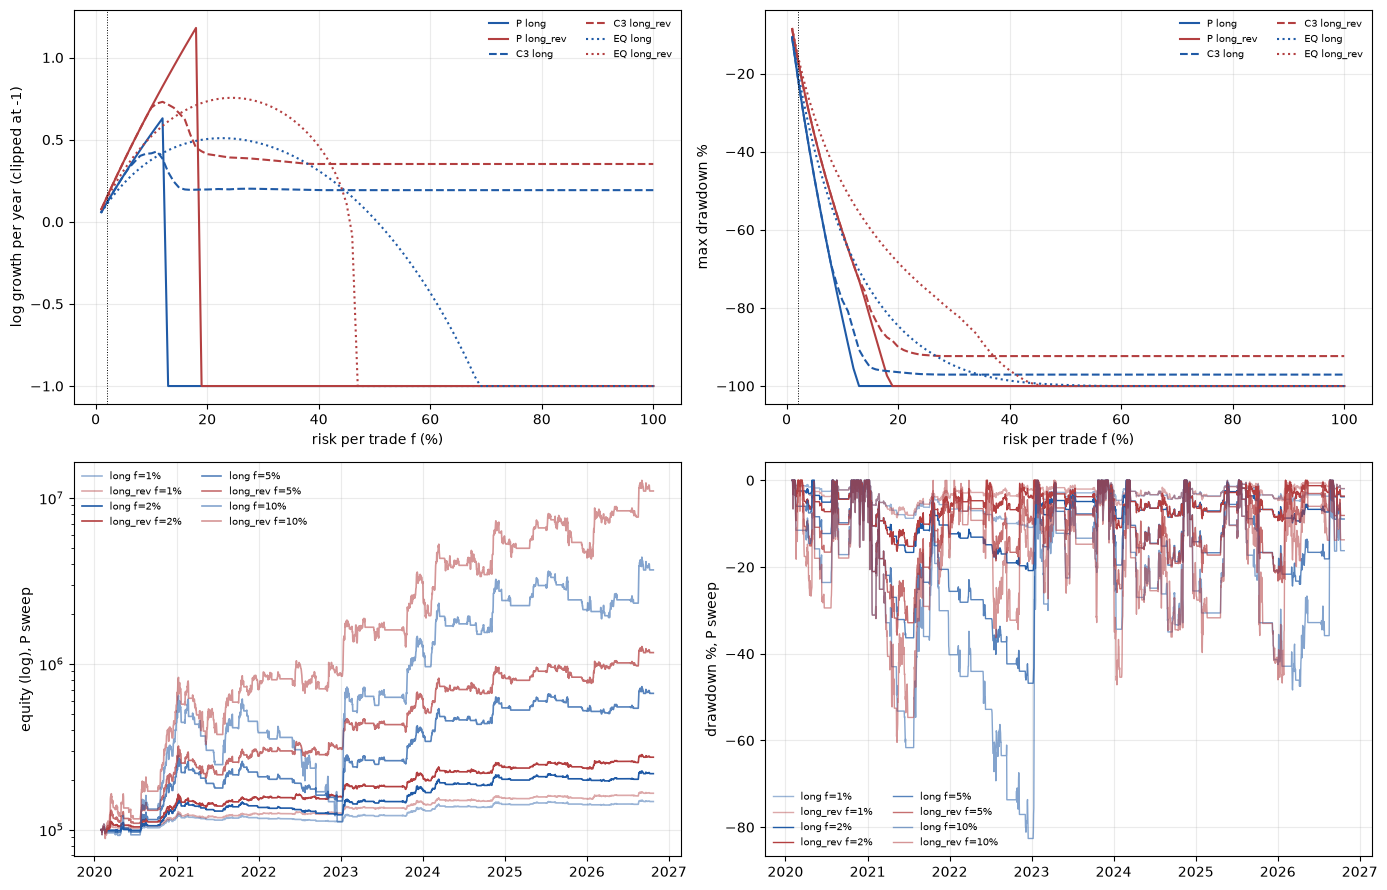

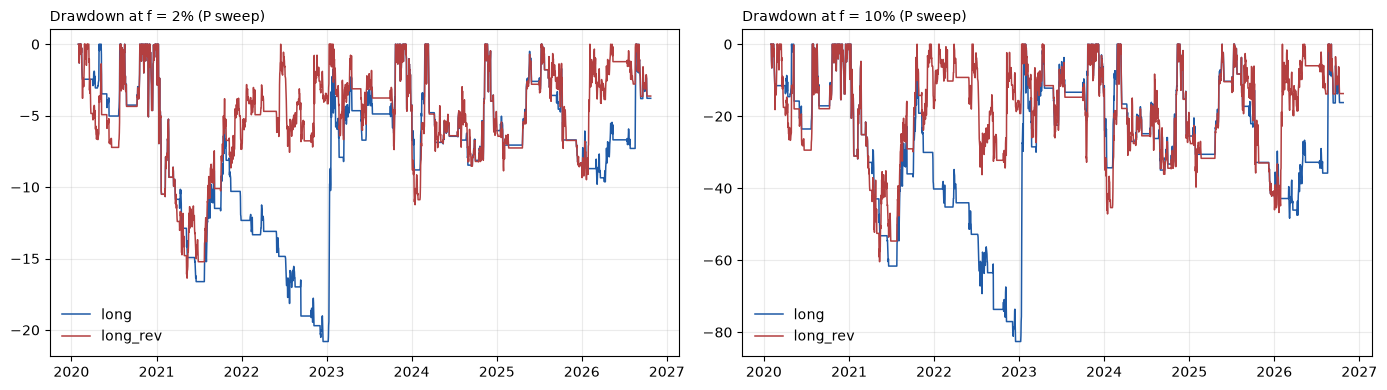

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
sty = {'long': dict(color='#1f5aa6'), 'long_rev': dict(color='#b33f40')}
for name, ls in (('P', '-'), ('C3', '--'), ('EQ', ':')):
    for v in ('long', 'long_rev'):
        t = TAB[(name, v)]
        axes[0, 0].plot(t.f * 100, t.log_growth_per_year.clip(lower=-1), ls=ls, label=f'{name} {v}', **sty[v])
        axes[0, 1].plot(t.f * 100, t.max_dd * 100, ls=ls, label=f'{name} {v}', **sty[v])
axes[0, 0].set_ylabel('log growth per year (clipped at -1)'); axes[0, 1].set_ylabel('max drawdown %')
for a in axes[0]:
    a.axvline(2, color='k', lw=0.7, ls=':'); a.set_xlabel('risk per trade f (%)'); a.grid(alpha=0.25); a.legend(frameon=False, fontsize=7, ncol=2)
for f_, al in ((0.01, 0.45), (0.02, 1.0), (0.05, 0.75), (0.1, 0.55)):
    for v in ('long', 'long_rev'):
        c = CUR[('P', v)][f_]
        axes[1, 0].plot(c.index, c, alpha=al, lw=1.2, label=f'{v} f={f_:.0%}', **sty[v])
        axes[1, 1].plot(c.index, (c / c.cummax() - 1) * 100, alpha=al, lw=1.0, label=f'{v} f={f_:.0%}', **sty[v])
axes[1, 0].set_yscale('log'); axes[1, 0].set_ylabel('equity (log), P sweep'); axes[1, 1].set_ylabel('drawdown %, P sweep')
for a in axes[1]:
    a.grid(alpha=0.25); a.legend(frameon=False, fontsize=7, ncol=2)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, f_ in zip(axes, (0.02, 0.1)):
    for v in ('long', 'long_rev'):
        c = CUR[('P', v)][f_]; ax.plot(c.index, (c / c.cummax() - 1) * 100, lw=1.1, label=v, **sty[v])
    ax.set_title(f'Drawdown at f = {f_:.0%} (P sweep)', loc='left', fontsize=10); ax.grid(alpha=0.25); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

## 6. Save

In [7]:
for (name, v), t in TAB.items():
    t.to_csv(OUT / f'09_sweep_{name}_{v}.csv', index=False)
SUM.to_csv(OUT / '09_summary.csv', index=False); PAIR.to_csv(OUT / '09_pair_P.csv', index=False)
pd.concat(SIDE, axis=0).to_csv(OUT / '09_side_by_side.csv')
pd.concat({v: CUR[('P', v)][[0.01, 0.02, 0.05, 0.1]] for v in ('long', 'long_rev')}, axis=1).to_csv(OUT / '09_curves_P_selected.csv')
git = subprocess.run(['git', 'rev-parse', '--short', 'HEAD'], cwd=str(ROOT), capture_output=True, text=True).stdout.strip()
(OUT / '09_manifest.json').write_text(json.dumps({'version': ts.VERSION, 'tb01_version': tb.VERSION, 'tb07_version': tr.VERSION, 'git': git,
    'python': platform.python_version(), 'created_utc': pd.Timestamp.now('UTC').isoformat(), 'start': str(START),
    'longs': int(len(L0)), 'reverse_shorts': int((L1.kind == 'reverse').sum()), 'synthetic': SYNTHETIC, 'descriptive_only': True}, indent=1))
print('saved to', OUT)

saved to D:\Projects\deribit_market_data\notebooks\Turtle_Breakout\09
